# 11-7. 새 데이터 셀 단위 승차인원 변화량 OLS`n
`n
비교일은 2024-10-17과 2025-11-06이며, 새 공급구조 유지 126개 격자를 사용한다.`n
`n
이 노트북은 새 데이터 전용 피처 통합파일 `17_새데이터_회귀분석_격자통합데이터.csv`가 구축된 뒤 실행한다.

In [1]:
# 프로젝트 루트(UROP) 자동 탐색 — 절대경로 없이 어느 컴퓨터에서도 동작
import sys
from pathlib import Path
UROP_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.py').is_file() and (p / 'code').is_dir())
for _d in [UROP_ROOT, *sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir() and d.name != '__pycache__')]:
    if str(_d) not in sys.path:
        sys.path.append(str(_d))

# 신규 10개 격자만 ORS 보행시간 조회 후 126개 통합 피처 저장
from pathlib import Path
from getpass import getpass
import time
import numpy as np
import pandas as pd
import requests
from IPython.display import display

PROJECT_DIR = UROP_ROOT
PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed' / 'gtx_a'
NEW_STABLE_PATH = PROCESSED_DIR / '16_새데이터_공급구조유지_250m격자.csv'
OLD_WALK_PATH = PROCESSED_DIR / '02_GTX역_보행접근성_250m격자.csv'
NEW_WALK_PATH = PROCESSED_DIR / '17_새데이터_GTX역_보행접근성_250m격자.csv'

stations = pd.DataFrame({
    '최근접 GTX-A역': ['운정중앙', '킨텍스', '대곡'],
    'GTX-A역 위도': [37.716670, 37.665000, 37.631626],
    'GTX-A역 경도': [126.728330, 126.748060, 126.811024],
})

def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0088
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp = np.radians(lat2 - lat1)
    dl = np.radians(lon2 - lon1)
    a = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

def nearest_station(lat, lon):
    distances = haversine_km(
        lat, lon,
        stations['GTX-A역 위도'].to_numpy(),
        stations['GTX-A역 경도'].to_numpy(),
    )
    idx = int(np.argmin(distances))
    row = stations.iloc[idx]
    return row, float(distances[idx])

def request_walk(api_key, start_lat, start_lon, end_lat, end_lon, retries=3):
    url = 'https://api.heigit.org/openrouteservice/v2/directions/foot-walking'
    headers = {'Authorization': api_key, 'Accept': 'application/geo+json'}
    params = {'start': f'{start_lon},{start_lat}', 'end': f'{end_lon},{end_lat}'}
    last_error = ''
    for attempt in range(retries):
        try:
            response = requests.get(url, headers=headers, params=params, timeout=60)
            response.raise_for_status()
            feature = response.json()['features'][0]
            summary = feature['properties']['summary']
            return float(summary['distance']), float(summary['duration']) / 60, 1, ''
        except Exception as exc:
            last_error = repr(exc)
            time.sleep(2 * (attempt + 1))
    return np.nan, np.nan, 0, last_error

stable = pd.read_csv(NEW_STABLE_PATH, encoding='utf-8-sig')
old = pd.read_csv(OLD_WALK_PATH, encoding='utf-8-sig')
stable['셀 ID'] = pd.to_numeric(stable['셀 ID'], errors='coerce').astype('Int64')
old['셀 ID'] = pd.to_numeric(old['셀 ID'], errors='coerce').astype('Int64')

walk_cols = [
    '셀 ID', '중심점 위도', '중심점 경도', '최근접 GTX-A역',
    'GTX-A역 위도', 'GTX-A역 경도', '최근접 GTX-A역 직선거리(km)',
    'ORS GET 보행거리(m)', 'ORS GET 보행시간(분)',
    'ORS GET API 성공', 'ORS GET API 오류',
]
reused = old[old['셀 ID'].isin(stable['셀 ID'])][walk_cols].copy()
missing = stable[~stable['셀 ID'].isin(reused['셀 ID'])][['셀 ID', '중심점 위도', '중심점 경도']].copy()

print(f'새 공급구조 유지 격자: {len(stable)}개')
print(f'기존 ORS 결과 재사용: {len(reused)}개')
print(f'신규 ORS 조회 대상: {len(missing)}개')
display(missing)

if len(missing):
    api_key = getpass('OpenRouteService API Key를 입력하세요: ').strip()
    if not api_key:
        raise ValueError('ORS API Key가 입력되지 않았습니다.')
    rows = []
    for number, (_, cell) in enumerate(missing.iterrows(), start=1):
        lat = float(cell['중심점 위도'])
        lon = float(cell['중심점 경도'])
        station, straight_km = nearest_station(lat, lon)
        distance_m, duration_min, success, error = request_walk(
            api_key, lat, lon,
            float(station['GTX-A역 위도']), float(station['GTX-A역 경도'])
        )
        rows.append({
            '셀 ID': int(cell['셀 ID']),
            '중심점 위도': lat,
            '중심점 경도': lon,
            '최근접 GTX-A역': station['최근접 GTX-A역'],
            'GTX-A역 위도': station['GTX-A역 위도'],
            'GTX-A역 경도': station['GTX-A역 경도'],
            '최근접 GTX-A역 직선거리(km)': straight_km,
            'ORS GET 보행거리(m)': distance_m,
            'ORS GET 보행시간(분)': duration_min,
            'ORS GET API 성공': success,
            'ORS GET API 오류': error,
        })
        print(f"[{number}/{len(missing)}] 셀 {int(cell['셀 ID'])}: {station['최근접 GTX-A역']} {duration_min:.2f}분" if success else f"[{number}/{len(missing)}] 셀 {int(cell['셀 ID'])}: 실패 {error}")
        time.sleep(1)
    new_rows = pd.DataFrame(rows)
else:
    new_rows = pd.DataFrame(columns=walk_cols)

walk_126 = pd.concat([reused, new_rows], ignore_index=True).sort_values('셀 ID')
walk_126.to_csv(NEW_WALK_PATH, index=False, encoding='utf-8-sig')
print(f'저장: {NEW_WALK_PATH}')
print(f'총 {len(walk_126)}개 / 성공 {pd.to_numeric(walk_126["ORS GET API 성공"], errors="coerce").fillna(0).sum():.0f}개')
if len(walk_126) != 126 or pd.to_numeric(walk_126['ORS GET 보행시간(분)'], errors='coerce').isna().any():
    raise RuntimeError('126개 보행시간이 모두 완성되지 않았습니다. 실패 행을 확인한 뒤 다시 실행하세요.')

새 공급구조 유지 격자: 126개
기존 ORS 결과 재사용: 116개
신규 ORS 조회 대상: 10개


,셀 ID,중심점 위도,중심점 경도
2,407,37.744448,126.803362
34,4768,37.760169,126.794700
47,7262,37.757967,126.803235
63,9146,37.743989,126.729589
68,9849,37.732742,126.732543
82,10801,37.755595,126.783391
84,11191,37.681816,126.886169
97,12466,37.726666,126.846082
99,12580,37.730634,126.755261
123,14884,37.742245,126.811895


[1/10] 셀 407: 운정중앙 116.54분
[2/10] 셀 4768: 운정중앙 130.69분
[3/10] 셀 7262: 운정중앙 139.99분
[4/10] 셀 9146: 운정중앙 49.58분
[5/10] 셀 9849: 운정중앙 29.63분
[6/10] 셀 10801: 운정중앙 116.91분
[7/10] 셀 11191: 대곡 141.79분
[8/10] 셀 12466: 운정중앙 170.65분
[9/10] 셀 12580: 운정중앙 43.28분
[10/10] 셀 14884: 운정중앙 121.98분
저장: c:\Users\금경훈\Desktop\Gachon\3-2\UROP\github_2026-UROP\gtx_a_bus_analysis\data\processed\17_새데이터_GTX역_보행접근성_250m격자.csv
총 126개 / 성공 126개


In [2]:
import sys
from pathlib import Path

PROJECT_DIR = UROP_ROOT
sys.path.insert(0, str(PROJECT_DIR))

from config import *
setup_notebook()

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from IPython.display import display

ID = '셀 ID'
NEW_MODEL_PATH = PROCESSED_DIR / '18_새데이터_회귀분석_격자통합데이터.csv'
model = read_csv(NEW_MODEL_PATH)
model[ID] = pd.to_numeric(model[ID], errors='coerce').astype('Int64')
model['change_all'] = pd.to_numeric(model['change_all'], errors='coerce')
model['walk_20_only'] = (model['walk_min'] <= 20).astype(float)

common = ['ic_access', 'competing_share', 'pop_20_50', 'buildings']
required = ['change_all', 'walk_min', 'walk_20', 'walk_20_60'] + common
for column in required:
    model[column] = pd.to_numeric(model[column], errors='coerce')
model = model.dropna(subset=required).copy()

print('분석 셀 수:', len(model))
print('셀 ID 중복:', model[ID].duplicated().sum())
print('종속변수: 2025년 종일 승차인원 - 2024년 종일 승차인원')
display(model[[ID, 'change_all', 'walk_min', 'walk_20', 'walk_20_60'] + common].head())

분석 셀 수: 126
셀 ID 중복: 0
종속변수: 2025년 종일 승차인원 - 2024년 종일 승차인원


,셀 ID,change_all,walk_min,walk_20,walk_20_60,ic_access,competing_share,pop_20_50,buildings
0,44,-178.0,51.650000,0.0,1.0,5.071,21.189591,937.0,18.0
1,76,-2.0,160.710000,0.0,0.0,1.921,0.000000,33.0,37.0
2,407,-52.0,116.541667,0.0,0.0,8.427,40.845070,24.0,27.0
3,559,-51.0,50.225000,0.0,1.0,0.319,0.000000,0.0,46.0
4,1064,-56.0,66.821667,0.0,0.0,5.920,20.512821,1487.0,17.0


## 1. 세 가지 OLS 추정

In [3]:
specs = {
    '모형1_보행시간_연속형': ['walk_min'] + common,
    '모형2_20분이내_더미': ['walk_20_only'] + common,
    '모형3_3구간_더미': ['walk_20', 'walk_20_60'] + common,
}

fits = {}
for name, features in specs.items():
    X = sm.add_constant(model[features].astype(float), has_constant='add')
    fits[name] = sm.OLS(model['change_all'], X).fit(cov_type='HC3')
    print('\n' + '=' * 90)
    print(name)
    print(fits[name].summary())


모형1_보행시간_연속형
                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.130
Model:                            OLS   Adj. R-squared:                  0.094
Method:                 Least Squares   F-statistic:                     3.009
Date:                   수, 07 10 2026   Prob (F-statistic):             0.0136
Time:                        14:04:47   Log-Likelihood:                -831.22
No. Observations:                 126   AIC:                             1674.
Df Residuals:                     120   BIC:                             1691.
Df Model:                           5                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const            -227.4278  

## 2. 모형 적합도 비교

In [4]:
comparison = pd.DataFrame([
    {
        '모형': name,
        '표본 수': int(fit.nobs),
        'R²': fit.rsquared,
        '수정 R²': fit.rsquared_adj,
        'AIC': fit.aic,
        'BIC': fit.bic,
        '모형 전체 p값': fit.f_pvalue,
        'RMSE': np.sqrt(np.mean(fit.resid ** 2)),
    }
    for name, fit in fits.items()
])
display(comparison.round(4))

,모형,표본 수,R²,수정 R²,AIC,BIC,모형 전체 p값,RMSE
0,모형1_보행시간_연속형,126,0.1303,0.0940,1674.4321,1691.4498,0.0136,177.3303
1,모형2_20분이내_더미,126,0.1358,0.0998,1673.6317,1690.6494,0.0171,176.7680
2,모형3_3구간_더미,126,0.1713,0.1296,1670.3383,1690.1923,0.0002,173.0936


## 3. 핵심 변수 계수와 p값 비교

In [5]:
labels = {
    'walk_min': 'GTX역 보행시간(분)',
    'walk_20_only': 'GTX역 보행 20분 이내(기준: 20분 초과)',
    'walk_20': 'GTX역 보행 20분 이내(기준: 60분 초과)',
    'walk_20_60': 'GTX역 보행 20~60분(기준: 60분 초과)',
    'ic_access': 'IC까지 도로거리(km)',
    'competing_share': 'GTX 경쟁 목적지 비율(%)',
    'pop_20_50': '2024년 20~50대 인구(명)',
    'buildings': '2024년 건축물 수(동)',
}

rows = []
for name, fit in fits.items():
    ci = fit.conf_int()
    for variable in specs[name]:
        rows.append({
            '모형': name,
            '변수': labels[variable],
            '계수(명)': fit.params[variable],
            'HC3 표준오차': fit.bse[variable],
            't값': fit.tvalues[variable],
            'p값': fit.pvalues[variable],
            '95% CI 하한': ci.loc[variable, 0],
            '95% CI 상한': ci.loc[variable, 1],
        })
result_table = pd.DataFrame(rows)
display(result_table.round(4))

,모형,변수,계수(명),HC3 표준오차,t값,p값,95% CI 하한,95% CI 상한
0,모형1_보행시간_연속형,GTX역 보행시간(분),1.1942,0.3467,3.4449,0.0006,0.5147,1.8736
1,모형1_보행시간_연속형,IC까지 도로거리(km),5.0490,4.8364,1.0440,0.2965,-4.4301,14.5282
2,모형1_보행시간_연속형,GTX 경쟁 목적지 비율(%),-0.8010,0.6010,-1.3328,0.1826,-1.9790,0.3770
3,모형1_보행시간_연속형,2024년 20~50대 인구(명),0.0137,0.0311,0.4411,0.6592,-0.0472,0.0746
4,모형1_보행시간_연속형,2024년 건축물 수(동),0.7853,0.3736,2.1018,0.0356,0.0530,1.5176
5,모형2_20분이내_더미,GTX역 보행 20분 이내(기준: 20분 초과),-185.1573,77.5633,-2.3872,0.0170,-337.1786,-33.1360
6,모형2_20분이내_더미,IC까지 도로거리(km),10.5580,5.4426,1.9399,0.0524,-0.1093,21.2252
7,모형2_20분이내_더미,GTX 경쟁 목적지 비율(%),-0.4652,0.6321,-0.7360,0.4617,-1.7040,0.7736
8,모형2_20분이내_더미,2024년 20~50대 인구(명),-0.0191,0.0250,-0.7652,0.4442,-0.0681,0.0299
9,모형2_20분이내_더미,2024년 건축물 수(동),0.9974,0.3778,2.6399,0.0083,0.2569,1.7379


## 해석 주의사항

- 계수의 단위는 **셀 전체 승차 변화량의 명(人) 차이**이다.
- 모형 2에서 20분 이내 계수는 20분 초과 셀과의 평균 변화량 차이다.
- 모형 3에서 두 보행시간 계수의 공통 기준은 60분 초과 셀이다.
- 이 모형에는 2024년 승차인원을 통제변수로 넣지 않았으므로 지역별 기존 승차규모 차이가 계수에 함께 반영될 수 있다. 2024년 승차규모 통제 모형은 별도의 강건성 분석으로 비교하는 것이 안전하다.

## 4. 기본모형: 보행시간 3구간 더미

세 모형 중 적합도와 해석 가능성을 고려해 3구간 더미 모형을 기본모형으로 지정한다. 60분 초과 셀이 기준집단이다.

In [6]:
BASE_FEATURES = ['walk_20', 'walk_20_60', 'ic_access', 'competing_share', 'pop_20_50', 'buildings']
X_base = sm.add_constant(model[BASE_FEATURES].astype(float), has_constant='add')
base_fit = sm.OLS(model['change_all'], X_base).fit(cov_type='HC3')
print(base_fit.summary())

base_ci = base_fit.conf_int().loc[BASE_FEATURES]
base_result = pd.DataFrame({
    '변수': [labels[v] for v in BASE_FEATURES],
    '계수(명)': [base_fit.params[v] for v in BASE_FEATURES],
    'HC3 표준오차': [base_fit.bse[v] for v in BASE_FEATURES],
    't값': [base_fit.tvalues[v] for v in BASE_FEATURES],
    'p값': [base_fit.pvalues[v] for v in BASE_FEATURES],
    '95% CI 하한': [base_ci.loc[v, 0] for v in BASE_FEATURES],
    '95% CI 상한': [base_ci.loc[v, 1] for v in BASE_FEATURES],
})
display(base_result.round(4))

                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.171
Model:                            OLS   Adj. R-squared:                  0.130
Method:                 Least Squares   F-statistic:                     4.863
Date:                   수, 07 10 2026   Prob (F-statistic):           0.000178
Time:                        14:07:15   Log-Likelihood:                -828.17
No. Observations:                 126   AIC:                             1670.
Df Residuals:                     119   BIC:                             1690.
Df Model:                           6                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             -72.9672     37.318     

,변수,계수(명),HC3 표준오차,t값,p값,95% CI 하한,95% CI 상한
0,GTX역 보행 20분 이내(기준: 60분 초과),-252.6426,76.7330,-3.2925,0.0010,-403.0366,-102.2487
1,GTX역 보행 20~60분(기준: 60분 초과),-89.2930,26.9244,-3.3164,0.0009,-142.0639,-36.5221
2,IC까지 도로거리(km),4.6912,4.8960,0.9582,0.3380,-4.9049,14.2872
3,GTX 경쟁 목적지 비율(%),-0.7000,0.6169,-1.1346,0.2565,-1.9092,0.5092
4,2024년 20~50대 인구(명),0.0010,0.0267,0.0388,0.9691,-0.0513,0.0534
5,2024년 건축물 수(동),0.9596,0.3651,2.6280,0.0086,0.2439,1.6753


## 5. 2024년 공시지가 추가 비교

공시지가는 GTX 개통 전 지역의 토지가치·개발 수준을 통제하는 변수로 사용한다. 원값은 `100만원/㎡` 단위로 바꾸어 해석하고, 분포의 비대칭을 줄이기 위해 자연로그 버전도 별도로 비교한다. 두 값을 동시에 넣지는 않는다.

In [7]:
LAND_PATH = PROCESSED_DIR / '18-1_새데이터_추가피처_250m격자.csv'
LAND_RAW = 'land_price_2024'
LAND_LOG = 'log_land_price_2024'

land = read_csv(LAND_PATH)
land[ID] = pd.to_numeric(land[ID], errors='coerce').astype('Int64')
land[LAND_RAW] = pd.to_numeric(land[LAND_RAW], errors='coerce')
land[LAND_LOG] = pd.to_numeric(land[LAND_LOG], errors='coerce')
land['land_price_million'] = land[LAND_RAW] / 1_000_000

model_land = model.merge(
    land[[ID, 'land_price_million', LAND_LOG]],
    on=ID, how='left', validate='one_to_one'
)

# 세 모형을 같은 130개 셀에서 비교해야 AIC·BIC 비교가 가능하다.
common_land_sample = model_land.dropna(
    subset=['change_all'] + BASE_FEATURES + ['land_price_million', LAND_LOG]
).copy()

land_specs = {
    '기본모형': BASE_FEATURES,
    '공시지가_원값_100만원단위': BASE_FEATURES + ['land_price_million'],
    '공시지가_자연로그': BASE_FEATURES + [LAND_LOG],
}
land_fits = {}
for name, features in land_specs.items():
    sample = common_land_sample.copy()
    X = sm.add_constant(sample[features].astype(float), has_constant='add')
    land_fits[name] = sm.OLS(sample['change_all'], X).fit(cov_type='HC3')

land_comparison = []
for name, fit in land_fits.items():
    land_variable = None if name == '기본모형' else land_specs[name][-1]
    land_comparison.append({
        '모형': name,
        '표본 수': int(fit.nobs),
        'R²': fit.rsquared,
        '수정 R²': fit.rsquared_adj,
        'AIC': fit.aic,
        'BIC': fit.bic,
        '공시지가 계수': np.nan if land_variable is None else fit.params[land_variable],
        '공시지가 p값': np.nan if land_variable is None else fit.pvalues[land_variable],
    })
display(pd.DataFrame(land_comparison).round(4))

for name, fit in land_fits.items():
    if name == '기본모형':
        continue
    print('\n' + '=' * 80)
    print(name)
    key_variables = BASE_FEATURES + [land_specs[name][-1]]
    display(pd.DataFrame({
        '계수': fit.params.loc[key_variables],
        'HC3 표준오차': fit.bse.loc[key_variables],
        'p값': fit.pvalues.loc[key_variables],
    }).round(4))

,모형,표본 수,R²,수정 R²,AIC,BIC,공시지가 계수,공시지가 p값
0,기본모형,124,0.1690,0.1264,1646.0006,1665.7426,NaN,NaN
1,공시지가_원값_100만원단위,124,0.3186,0.2775,1623.3915,1645.9538,-122.1604,0.1245
2,공시지가_자연로그,124,0.1986,0.1502,1643.5067,1666.0689,-65.8185,0.2581



공시지가_원값_100만원단위


,계수,HC3 표준오차,p값
walk_20,-260.5777,86.0204,0.0025
walk_20_60,-33.4555,38.9593,0.3905
ic_access,-0.0766,4.1490,0.9853
competing_share,-0.5442,0.4985,0.2749
pop_20_50,0.0812,0.0559,0.1462
buildings,1.2397,0.4724,0.0087
land_price_million,-122.1604,79.5199,0.1245



공시지가_자연로그


,계수,HC3 표준오차,p값
walk_20,-243.7705,82.9064,0.0033
walk_20_60,-55.5969,29.4931,0.0594
ic_access,3.1303,4.5413,0.4906
competing_share,-0.6569,0.5695,0.2487
pop_20_50,0.0459,0.0471,0.3300
buildings,1.2458,0.5224,0.0171
log_land_price_2024,-65.8185,58.2028,0.2581


## 5-1. 20~50대 인구 수준을 인구 증감으로 교체

기본모형의 `2024년 20~50대 인구`를 제외하고 `2024→2025년 20~50대 인구 증감(100명 단위)`을 투입한다. 계수는 20~50대 인구가 100명 증가할 때 셀의 종일 승차 변화량이 몇 명 달라지는지를 의미한다.

In [8]:
POP_CHANGE_PATH = PROCESSED_DIR / '11_20~50대인구변화_2024_2025_250m격자.csv'
POP_CHANGE_SOURCE = '20~50대 인구 증감(100명)'
POP_CHANGE = 'pop_change_100'

pop_change = read_csv(POP_CHANGE_PATH)
pop_change[ID] = pd.to_numeric(pop_change[ID], errors='coerce').astype('Int64')
pop_change[POP_CHANGE_SOURCE] = pd.to_numeric(
    pop_change[POP_CHANGE_SOURCE], errors='coerce'
)
pop_change = pop_change[[ID, POP_CHANGE_SOURCE]].rename(
    columns={POP_CHANGE_SOURCE: POP_CHANGE}
)

model_pop_change = model.merge(pop_change, on=ID, how='left', validate='one_to_one')
POP_CHANGE_FEATURES = [
    'walk_20', 'walk_20_60', 'ic_access', 'competing_share',
    POP_CHANGE, 'buildings'
]
pop_sample = model_pop_change.dropna(
    subset=['change_all'] + POP_CHANGE_FEATURES
).copy()
X_pop_change = sm.add_constant(
    pop_sample[POP_CHANGE_FEATURES].astype(float), has_constant='add'
)
pop_change_fit = sm.OLS(
    pop_sample['change_all'], X_pop_change
).fit(cov_type='HC3')
print(pop_change_fit.summary())

POP_CHANGE_LABELS = {
    'walk_20': 'GTX 보행 20분 이내',
    'walk_20_60': 'GTX 보행 20~60분',
    'ic_access': 'IC까지 도로거리',
    'competing_share': 'GTX 경쟁 목적지 비율',
    'buildings': '2024년 건축물 수',
    POP_CHANGE: '20~50대 인구 증감(100명)',
}
pop_ci = pop_change_fit.conf_int().loc[POP_CHANGE_FEATURES]
pop_change_result = pd.DataFrame({
    '변수': [POP_CHANGE_LABELS.get(v, v) for v in POP_CHANGE_FEATURES],
    '계수(명)': [pop_change_fit.params[v] for v in POP_CHANGE_FEATURES],
    'HC3 표준오차': [pop_change_fit.bse[v] for v in POP_CHANGE_FEATURES],
    't값': [pop_change_fit.tvalues[v] for v in POP_CHANGE_FEATURES],
    'p값': [pop_change_fit.pvalues[v] for v in POP_CHANGE_FEATURES],
    '95% CI 하한': [pop_ci.loc[v, 0] for v in POP_CHANGE_FEATURES],
    '95% CI 상한': [pop_ci.loc[v, 1] for v in POP_CHANGE_FEATURES],
})
display(pop_change_result.round(4))

population_comparison = pd.DataFrame([
    {
        '모형': '2024년 20~50대 인구 수준',
        '표본 수': int(base_fit.nobs),
        'R²': base_fit.rsquared,
        '수정 R²': base_fit.rsquared_adj,
        'AIC': base_fit.aic,
        'BIC': base_fit.bic,
        '인구변수 계수': base_fit.params['pop_20_50'],
        '인구변수 p값': base_fit.pvalues['pop_20_50'],
    },
    {
        '모형': '20~50대 인구 증감(100명)',
        '표본 수': int(pop_change_fit.nobs),
        'R²': pop_change_fit.rsquared,
        '수정 R²': pop_change_fit.rsquared_adj,
        'AIC': pop_change_fit.aic,
        'BIC': pop_change_fit.bic,
        '인구변수 계수': pop_change_fit.params[POP_CHANGE],
        '인구변수 p값': pop_change_fit.pvalues[POP_CHANGE],
    },
])
display(population_comparison.round(4))

                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.177
Model:                            OLS   Adj. R-squared:                  0.132
Method:                 Least Squares   F-statistic:                     5.011
Date:                   수, 07 10 2026   Prob (F-statistic):           0.000143
Time:                        14:08:26   Log-Likelihood:                -765.83
No. Observations:                 116   AIC:                             1546.
Df Residuals:                     109   BIC:                             1565.
Df Model:                           6                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             -83.0085     39.837     

,변수,계수(명),HC3 표준오차,t값,p값,95% CI 하한,95% CI 상한
0,GTX 보행 20분 이내,-245.7121,75.1202,-3.2709,0.0011,-392.9451,-98.4792
1,GTX 보행 20~60분,-96.4087,25.8106,-3.7352,0.0002,-146.9966,-45.8209
2,IC까지 도로거리,6.0446,5.7939,1.0433,0.2968,-5.3112,17.4005
3,GTX 경쟁 목적지 비율,-1.1350,0.9330,-1.2166,0.2238,-2.9636,0.6935
4,20~50대 인구 증감(100명),-14.9782,13.7619,-1.0884,0.2764,-41.9510,11.9946
5,2024년 건축물 수,1.1147,0.3973,2.8059,0.0050,0.3361,1.8933


,모형,표본 수,R²,수정 R²,AIC,BIC,인구변수 계수,인구변수 p값
0,2024년 20~50대 인구 수준,126,0.1713,0.1296,1670.3383,1690.1923,0.0010,0.9691
1,20~50대 인구 증감(100명),116,0.1770,0.1317,1545.6554,1564.9305,-14.9782,0.2764


## 5-2. 연령대별 인구 증감을 하나씩 투입

20대·30대·40대·50대 인구 증감을 각각 하나씩 투입한 네 모형을 비교한다. 단위는 1명이다.

In [9]:
AGE_CHANGE_SOURCE = {'pop_change_20': '20대 인구 증감', 'pop_change_30': '30대 인구 증감', 'pop_change_40': '40대 인구 증감', 'pop_change_50': '50대 인구 증감'}
AGE_LEVEL_SOURCE = {'pop_2024_20': '2024년 20대 인구', 'pop_2024_30': '2024년 30대 인구', 'pop_2024_40': '2024년 40대 인구', 'pop_2024_50': '2024년 50대 인구'}
population_full = read_csv(POP_CHANGE_PATH)
population_full[ID] = pd.to_numeric(population_full[ID], errors='coerce').astype('Int64')
for age in [20, 30, 40, 50]:
    before = pd.to_numeric(population_full[f'2024년 {age}대 인구'], errors='coerce')
    after = pd.to_numeric(population_full[f'2025년 {age}대 인구'], errors='coerce')
    population_full[f'pop_change_{age}'] = after - before
    population_full[f'pop_2024_{age}'] = before
age_model = model.merge(population_full[[ID] + list(AGE_CHANGE_SOURCE) + list(AGE_LEVEL_SOURCE)], on=ID, how='left', validate='one_to_one')
COMMON_WITHOUT_POP = ['walk_20', 'walk_20_60', 'ic_access', 'competing_share', 'buildings']
age_separate_fits, age_separate_rows = {}, []
for variable, source_name in AGE_CHANGE_SOURCE.items():
    features = COMMON_WITHOUT_POP + [variable]
    sample = age_model.dropna(subset=['change_all'] + features).copy()
    X = sm.add_constant(sample[features].astype(float), has_constant='add')
    fit = sm.OLS(sample['change_all'], X).fit(cov_type='HC3')
    age_separate_fits[variable] = fit
    age_separate_rows.append({'인구변수': source_name + '(명)', '표본 수': int(fit.nobs), '인구 계수': fit.params[variable], '인구 p값': fit.pvalues[variable], '20분 이내 계수': fit.params['walk_20'], '20분 이내 p값': fit.pvalues['walk_20'], '20~60분 계수': fit.params['walk_20_60'], '20~60분 p값': fit.pvalues['walk_20_60'], 'R²': fit.rsquared, '수정 R²': fit.rsquared_adj, 'AIC': fit.aic, 'BIC': fit.bic, '전체 p값': fit.f_pvalue})
age_separate_result = pd.DataFrame(age_separate_rows)
display(age_separate_result.round(4))

,인구변수,표본 수,인구 계수,인구 p값,20분 이내 계수,20분 이내 p값,20~60분 계수,20~60분 p값,R²,수정 R²,AIC,BIC,전체 p값
0,20대 인구 증감(명),116,-0.6844,0.2380,-243.5389,0.0011,-95.8539,0.0002,0.1779,0.1326,1545.5261,1564.8012,0.0002
1,30대 인구 증감(명),116,-0.5602,0.2160,-252.7046,0.0006,-97.8796,0.0002,0.1767,0.1314,1545.6878,1564.9629,0.0001
2,40대 인구 증감(명),116,-0.5354,0.4238,-248.6847,0.0010,-96.9669,0.0003,0.1762,0.1309,1545.7612,1565.0364,0.0001
3,50대 인구 증감(명),116,-0.3041,0.4209,-243.7962,0.0013,-94.1259,0.0001,0.1743,0.1288,1546.0316,1565.3067,0.0001


## 5-3. 연령대별 인구 증감을 동시에 투입

네 연령대의 인구 증감을 동시에 투입하고 VIF를 확인한다.

In [10]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
AGE_CHANGE_FEATURES = COMMON_WITHOUT_POP + list(AGE_CHANGE_SOURCE)
age_change_sample = age_model.dropna(subset=['change_all'] + AGE_CHANGE_FEATURES).copy()
X_age_change = sm.add_constant(age_change_sample[AGE_CHANGE_FEATURES].astype(float), has_constant='add')
age_change_all_fit = sm.OLS(age_change_sample['change_all'], X_age_change).fit(cov_type='HC3')
display(pd.DataFrame({'변수': [AGE_CHANGE_SOURCE.get(v, labels.get(v, v)) for v in AGE_CHANGE_FEATURES], '계수': age_change_all_fit.params.loc[AGE_CHANGE_FEATURES].values, 'HC3 표준오차': age_change_all_fit.bse.loc[AGE_CHANGE_FEATURES].values, 't값': age_change_all_fit.tvalues.loc[AGE_CHANGE_FEATURES].values, 'p값': age_change_all_fit.pvalues.loc[AGE_CHANGE_FEATURES].values}).round(4))
age_change_vif = pd.DataFrame({'변수': [AGE_CHANGE_SOURCE.get(v, labels.get(v, v)) for v in AGE_CHANGE_FEATURES], 'VIF': [variance_inflation_factor(X_age_change.to_numpy(), X_age_change.columns.get_loc(v)) for v in AGE_CHANGE_FEATURES]}).sort_values('VIF', ascending=False)
display(age_change_vif.round(3))
print('R²:', round(age_change_all_fit.rsquared, 4), '| 수정 R²:', round(age_change_all_fit.rsquared_adj, 4), '| 전체 p값:', round(age_change_all_fit.f_pvalue, 4))

,변수,계수,HC3 표준오차,t값,p값
0,GTX역 보행 20분 이내(기준: 60분 초과),-259.2180,76.9607,-3.3682,0.0008
1,GTX역 보행 20~60분(기준: 60분 초과),-102.1212,27.7238,-3.6835,0.0002
2,IC까지 도로거리(km),6.4087,5.6769,1.1289,0.2589
3,GTX 경쟁 목적지 비율(%),-1.2239,0.8679,-1.4102,0.1585
4,2024년 건축물 수(동),1.1365,0.4055,2.8025,0.0051
5,20대 인구 증감,-1.5508,1.2991,-1.1937,0.2326
6,30대 인구 증감,-0.6101,0.8433,-0.7235,0.4694
7,40대 인구 증감,-0.0630,1.3870,-0.0454,0.9638
8,50대 인구 증감,1.0054,0.9251,1.0867,0.2772


,변수,VIF
8,50대 인구 증감,7.400
5,20대 인구 증감,6.289
7,40대 인구 증감,3.263
6,30대 인구 증감,2.574
1,GTX역 보행 20~60분(기준: 60분 초과),1.408
0,GTX역 보행 20분 이내(기준: 60분 초과),1.404
2,IC까지 도로거리(km),1.332
3,GTX 경쟁 목적지 비율(%),1.236
4,2024년 건축물 수(동),1.036


R²: 0.1831 | 수정 R²: 0.1137 | 전체 p값: 0.0004


## 5-4. 2024년 연령대별 인구 수준을 동시에 투입

증감 대신 개통 전인 2024년 20대·30대·40대·50대 인구를 동시에 투입한다. 단위는 1명이다.

In [11]:
AGE_LEVEL_FEATURES = COMMON_WITHOUT_POP + list(AGE_LEVEL_SOURCE)
age_level_sample = age_model.dropna(subset=['change_all'] + AGE_LEVEL_FEATURES).copy()
X_age_level = sm.add_constant(age_level_sample[AGE_LEVEL_FEATURES].astype(float), has_constant='add')
age_level_fit = sm.OLS(age_level_sample['change_all'], X_age_level).fit(cov_type='HC3')
display(pd.DataFrame({'변수': [AGE_LEVEL_SOURCE.get(v, labels.get(v, v)) for v in AGE_LEVEL_FEATURES], '계수': age_level_fit.params.loc[AGE_LEVEL_FEATURES].values, 'HC3 표준오차': age_level_fit.bse.loc[AGE_LEVEL_FEATURES].values, 't값': age_level_fit.tvalues.loc[AGE_LEVEL_FEATURES].values, 'p값': age_level_fit.pvalues.loc[AGE_LEVEL_FEATURES].values}).round(4))
age_level_vif = pd.DataFrame({'변수': [AGE_LEVEL_SOURCE.get(v, labels.get(v, v)) for v in AGE_LEVEL_FEATURES], 'VIF': [variance_inflation_factor(X_age_level.to_numpy(), X_age_level.columns.get_loc(v)) for v in AGE_LEVEL_FEATURES]}).sort_values('VIF', ascending=False)
display(age_level_vif.round(3))
age_model_comparison = pd.DataFrame([{'모형': '기본모형_20~50대 합계', 'R²': base_fit.rsquared, '수정 R²': base_fit.rsquared_adj, 'AIC': base_fit.aic, 'BIC': base_fit.bic, '전체 p값': base_fit.f_pvalue}, {'모형': '연령대별 증감_동시', 'R²': age_change_all_fit.rsquared, '수정 R²': age_change_all_fit.rsquared_adj, 'AIC': age_change_all_fit.aic, 'BIC': age_change_all_fit.bic, '전체 p값': age_change_all_fit.f_pvalue}, {'모형': '2024년 연령대별 수준_동시', 'R²': age_level_fit.rsquared, '수정 R²': age_level_fit.rsquared_adj, 'AIC': age_level_fit.aic, 'BIC': age_level_fit.bic, '전체 p값': age_level_fit.f_pvalue}])
display(age_model_comparison.round(4))

,변수,계수,HC3 표준오차,t값,p값
0,GTX역 보행 20분 이내(기준: 60분 초과),-237.8768,98.1919,-2.4226,0.0154
1,GTX역 보행 20~60분(기준: 60분 초과),-73.2675,28.6192,-2.5601,0.0105
2,IC까지 도로거리(km),2.6611,5.1339,0.5183,0.6042
3,GTX 경쟁 목적지 비율(%),-0.5052,0.9012,-0.5605,0.5751
4,2024년 건축물 수(동),1.1397,0.5659,2.0141,0.0440
5,2024년 20대 인구,-2.0619,2.2151,-0.9308,0.3519
6,2024년 30대 인구,-0.3150,0.3592,-0.8770,0.3805
7,2024년 40대 인구,-0.0046,0.4218,-0.0110,0.9913
8,2024년 50대 인구,1.5196,1.5321,0.9918,0.3213


,변수,VIF
8,2024년 50대 인구,22.709
5,2024년 20대 인구,20.623
7,2024년 40대 인구,7.314
6,2024년 30대 인구,6.278
0,GTX역 보행 20분 이내(기준: 60분 초과),1.628
1,GTX역 보행 20~60분(기준: 60분 초과),1.497
2,IC까지 도로거리(km),1.370
3,GTX 경쟁 목적지 비율(%),1.170
4,2024년 건축물 수(동),1.040


,모형,R²,수정 R²,AIC,BIC,전체 p값
0,기본모형_20~50대 합계,0.1713,0.1296,1670.3383,1690.1923,0.0002
1,연령대별 증감_동시,0.1831,0.1137,1550.7920,1578.3279,0.0004
2,2024년 연령대별 수준_동시,0.3018,0.2425,1532.5717,1560.1076,0.0118


## 6. 시간대별 셀 단위 변화량 분석

기본모형에서 유의했던 GTX역 보행시간 효과가 어느 시간대에 집중되는지 확인한다. 각 시간대별로 132개 셀의 승차인원을 합산하고, `2025년 승차−2024년 승차`를 종속변수로 사용해 기본모형과 동일한 OLS-HC3를 각각 추정한다.

- 새벽: 00~05시
- 출근: 06~09시
- 낮: 10~15시
- 저녁: 16~23시

In [16]:
TIME_LABELS = ['새벽(00~05)', '출근(06~09)', '낮(10~15)', '저녁(16~23)']
hour_to_band = {
    hour: ('새벽(00~05)' if hour <= 5 else
           '출근(06~09)' if hour <= 9 else
           '낮(10~15)' if hour <= 15 else '저녁(16~23)')
    for hour in range(24)
}

TIME_BAND_CELL_PATH = PROCESSED_DIR / '18-2_새데이터_시간대별_승차인원_셀.csv'
time_counts = read_csv(TIME_BAND_CELL_PATH).rename(columns={
    'board_2024': 'y2024_time',
    'board_2025': 'y2025_time',
    'change': 'change_time',
})
time_counts[ID] = pd.to_numeric(time_counts[ID], errors='coerce').astype('Int64')
time_counts['시간대'] = time_counts['시간대'].replace({
    '새벽': '새벽(00~05)', '출근': '출근(06~09)',
    '낮': '낮(10~15)', '저녁': '저녁(16~23)'
})
model['walk_group'] = np.select(
    [model['walk_20'].eq(1), model['walk_20_60'].eq(1)],
    ['20분 이내', '20~60분'],
    default='60분 초과'
)

time_model = time_counts.merge(
    model[[ID, 'walk_group'] + BASE_FEATURES],
    on=ID, how='left', validate='many_to_one'
)
print('시간대별 셀 수')
display(time_model.groupby('시간대', sort=False)[ID].nunique().reindex(TIME_LABELS).to_frame('셀 수'))

시간대별 셀 수


,셀 수
시간대,
새벽(00~05),126
출근(06~09),126
낮(10~15),126
저녁(16~23),126


### 6-1. 시간대·보행시간 구간별 실제 승차 변화율

walk_group,20~60분,20분 이내,60분 초과
시간대,,,
새벽(00~05),-63.7,-79.7,-26.1
출근(06~09),-68.5,-76.4,-68.1
낮(10~15),-68.6,-75.0,-60.6
저녁(16~23),-67.8,-64.5,-61.6


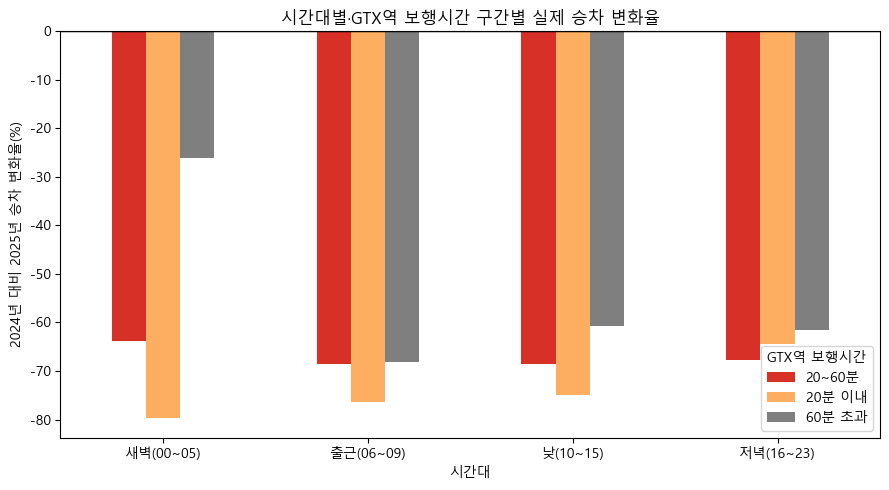

In [17]:
time_summary = (
    time_model.groupby(['시간대', 'walk_group'], observed=True)[['y2024_time', 'y2025_time']]
    .sum()
)
time_summary['실제 변화율(%)'] = np.where(
    time_summary['y2024_time'] > 0,
    (time_summary['y2025_time'] / time_summary['y2024_time'] - 1) * 100,
    np.nan,
)
time_rate_table = (
    time_summary['실제 변화율(%)'].unstack('walk_group')
    .reindex(TIME_LABELS)
)
display(time_rate_table.round(1))

ax = time_rate_table.plot.bar(
    figsize=(9, 5), rot=0, color=['#d73027', '#fdae61', '#7f7f7f']
)
ax.axhline(0, color='black', linewidth=1)
ax.set_xlabel('시간대')
ax.set_ylabel('2024년 대비 2025년 승차 변화율(%)')
ax.set_title('시간대별·GTX역 보행시간 구간별 실제 승차 변화율')
ax.legend(title='GTX역 보행시간')
plt.tight_layout()
plt.show()

### 6-2. 시간대별 기본모형 OLS-HC3

In [18]:
time_fits = {}
time_rows = []
for time_label in TIME_LABELS:
    frame = time_model[time_model['시간대'] == time_label].dropna(
        subset=['change_time'] + BASE_FEATURES
    ).copy()
    X = sm.add_constant(frame[BASE_FEATURES].astype(float), has_constant='add')
    fit = sm.OLS(frame['change_time'], X).fit(cov_type='HC3')
    time_fits[time_label] = fit
    time_rows.append({
        '시간대': time_label,
        '셀 수': int(fit.nobs),
        '20분 이내 계수(명)': fit.params['walk_20'],
        '20분 이내 p값': fit.pvalues['walk_20'],
        '20~60분 계수(명)': fit.params['walk_20_60'],
        '20~60분 p값': fit.pvalues['walk_20_60'],
        'R²': fit.rsquared,
        '수정 R²': fit.rsquared_adj,
        '모형 전체 p값': fit.f_pvalue,
    })
time_result = pd.DataFrame(time_rows)
display(time_result.round(4))

,시간대,셀 수,20분 이내 계수(명),20분 이내 p값,20~60분 계수(명),20~60분 p값,R²,수정 R²,모형 전체 p값
0,새벽(00~05),126,-20.1796,0.0016,-7.4620,0.0000,0.2609,0.2237,0.0000
1,출근(06~09),126,-110.3775,0.0002,-39.5131,0.0008,0.1917,0.1510,0.0000
2,낮(10~15),126,-67.6931,0.0213,-22.5305,0.0032,0.1678,0.1259,0.0034
3,저녁(16~23),126,-54.3926,0.1248,-19.7873,0.0151,0.0976,0.0521,0.1806


### 6-3. 시간대별 보행시간 효과 시각화

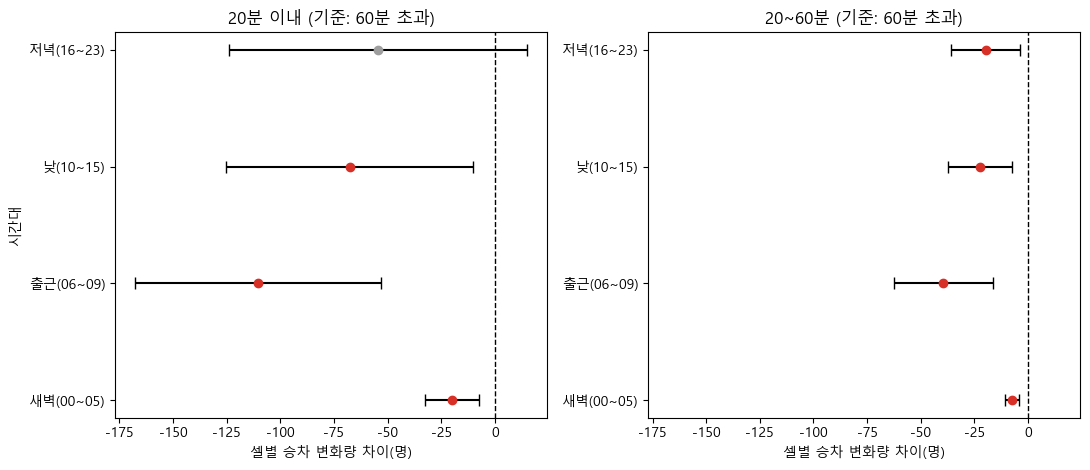

In [19]:
import matplotlib.pyplot as plt

plot_rows = []
for time_label, fit in time_fits.items():
    ci = fit.conf_int()
    for variable, group_label in [('walk_20', '20분 이내'), ('walk_20_60', '20~60분')]:
        plot_rows.append({
            '시간대': time_label,
            '구간': group_label,
            '계수': fit.params[variable],
            '하한': ci.loc[variable, 0],
            '상한': ci.loc[variable, 1],
            'p값': fit.pvalues[variable],
        })
plot_time = pd.DataFrame(plot_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharex=True)
for ax, group_label in zip(axes, ['20분 이내', '20~60분']):
    part = plot_time[plot_time['구간'] == group_label].set_index('시간대').reindex(TIME_LABELS).reset_index()
    y = np.arange(len(part))
    x = part['계수'].to_numpy()
    xerr = np.vstack([x - part['하한'].to_numpy(), part['상한'].to_numpy() - x])
    colors = ['#d73027' if p < 0.05 else '#9e9e9e' for p in part['p값']]
    for idx in range(len(part)):
        ax.errorbar(x[idx], y[idx], xerr=[[xerr[0, idx]], [xerr[1, idx]]],
                    fmt='o', color=colors[idx], ecolor='black', capsize=4)
    ax.axvline(0, color='black', linestyle='--', linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(part['시간대'])
    ax.set_title(group_label + ' (기준: 60분 초과)')
    ax.set_xlabel('셀별 승차 변화량 차이(명)')
axes[0].set_ylabel('시간대')
plt.tight_layout()
plt.show()

### 6-4. 시간대별 전체 변수 결과

각 시간대 모형에 포함된 6개 독립변수의 계수, HC3 표준오차, t값, p값과 모형 적합도를 모두 출력한다.

In [20]:
full_time_rows = []
for time_label, fit in time_fits.items():
    ci = fit.conf_int()
    for variable in BASE_FEATURES:
        full_time_rows.append({
            '시간대': time_label,
            '변수': labels[variable],
            '계수(명)': fit.params[variable],
            'HC3 표준오차': fit.bse[variable],
            't값': fit.tvalues[variable],
            'p값': fit.pvalues[variable],
            '95% CI 하한': ci.loc[variable, 0],
            '95% CI 상한': ci.loc[variable, 1],
            '유의성': ('***' if fit.pvalues[variable] < 0.01 else
                     '**' if fit.pvalues[variable] < 0.05 else
                     '*' if fit.pvalues[variable] < 0.10 else ''),
        })
full_time_result = pd.DataFrame(full_time_rows)
display(full_time_result.round(4))

print('시간대별 모형 적합도')
display(time_result[[
    '시간대', '셀 수', 'R²', '수정 R²', '모형 전체 p값'
]].round(4))

print('시간대별 변수 p값 비교')
pvalue_table = full_time_result.pivot(index='변수', columns='시간대', values='p값')
display(pvalue_table.reindex(columns=TIME_LABELS).round(4))

,시간대,변수,계수(명),HC3 표준오차,t값,p값,95% CI 하한,95% CI 상한,유의성
0,새벽(00~05),GTX역 보행 20분 이내(기준: 60분 초과),-20.1796,6.4017,-3.1522,0.0016,-32.7267,-7.6324,***
1,새벽(00~05),GTX역 보행 20~60분(기준: 60분 초과),-7.4620,1.6636,-4.4854,0.0000,-10.7227,-4.2014,***
2,새벽(00~05),IC까지 도로거리(km),-0.0448,0.2634,-0.1702,0.8648,-0.5612,0.4715,
3,새벽(00~05),GTX 경쟁 목적지 비율(%),-0.0241,0.0331,-0.7285,0.4663,-0.0889,0.0407,
4,새벽(00~05),2024년 20~50대 인구(명),-0.0018,0.0021,-0.8716,0.3834,-0.0059,0.0023,
5,새벽(00~05),2024년 건축물 수(동),0.0245,0.0243,1.0080,0.3134,-0.0231,0.0720,
6,출근(06~09),GTX역 보행 20분 이내(기준: 60분 초과),-110.3775,29.3231,-3.7642,0.0002,-167.8498,-52.9051,***
7,출근(06~09),GTX역 보행 20~60분(기준: 60분 초과),-39.5131,11.7314,-3.3681,0.0008,-62.5062,-16.5200,***
8,출근(06~09),IC까지 도로거리(km),-0.8038,1.8507,-0.4343,0.6641,-4.4311,2.8236,
9,출근(06~09),GTX 경쟁 목적지 비율(%),-0.2494,0.2399,-1.0399,0.2984,-0.7195,0.2207,


시간대별 모형 적합도


,시간대,셀 수,R²,수정 R²,모형 전체 p값
0,새벽(00~05),126,0.2609,0.2237,0.0000
1,출근(06~09),126,0.1917,0.1510,0.0000
2,낮(10~15),126,0.1678,0.1259,0.0034
3,저녁(16~23),126,0.0976,0.0521,0.1806


시간대별 변수 p값 비교


시간대,새벽(00~05),출근(06~09),낮(10~15),저녁(16~23)
변수,,,,
2024년 20~50대 인구(명),0.3834,0.3394,0.7892,0.2746
2024년 건축물 수(동),0.3134,0.0172,0.0298,0.0316
GTX 경쟁 목적지 비율(%),0.4663,0.2984,0.2300,0.3245
GTX역 보행 20~60분(기준: 60분 초과),0.0000,0.0008,0.0032,0.0151
GTX역 보행 20분 이내(기준: 60분 초과),0.0016,0.0002,0.0213,0.1248
IC까지 도로거리(km),0.8648,0.6641,0.0884,0.0981


## 7. 기본모형 다중공선성 진단

기본모형에 포함된 6개 독립변수의 VIF와 상관계수 히트맵을 확인한다. 일반적으로 VIF가 10 이상이면 다중공선성을 의심하며, 엄격하게는 5를 기준으로 사용한다.

기본모형 독립변수 VIF


,변수,VIF,판단
0,GTX 보행 20~60분,1.526,문제 없음
1,GTX 보행 20분 이내,1.315,문제 없음
2,IC까지 도로거리,1.299,문제 없음
3,2024년 20~50대 인구,1.107,문제 없음
4,GTX 경쟁 목적지 비율,1.088,문제 없음
5,2024년 건축물 수,1.014,문제 없음


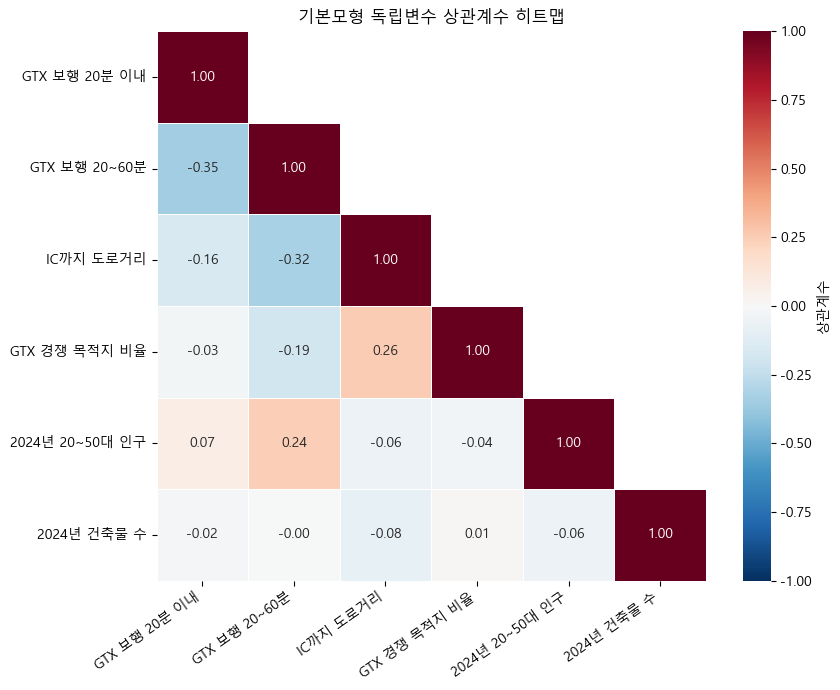

최대 VIF: 1.526


In [21]:
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

VIF_LABELS = {
    'walk_20': 'GTX 보행 20분 이내',
    'walk_20_60': 'GTX 보행 20~60분',
    'ic_access': 'IC까지 도로거리',
    'competing_share': 'GTX 경쟁 목적지 비율',
    'pop_20_50': '2024년 20~50대 인구',
    'buildings': '2024년 건축물 수',
}

vif_x = model[BASE_FEATURES].astype(float).dropna().copy()
vif_design = sm.add_constant(vif_x, has_constant='add')
vif_table = pd.DataFrame({
    '변수': [VIF_LABELS[v] for v in BASE_FEATURES],
    'VIF': [
        variance_inflation_factor(vif_design.to_numpy(), vif_design.columns.get_loc(v))
        for v in BASE_FEATURES
    ],
}).sort_values('VIF', ascending=False).reset_index(drop=True)
vif_table['판단'] = np.select(
    [vif_table['VIF'] >= 10, vif_table['VIF'] >= 5],
    ['다중공선성 높음', '주의'],
    default='문제 없음',
)
print('기본모형 독립변수 VIF')
display(vif_table.round(3))

corr = vif_x.rename(columns=VIF_LABELS).corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
    vmin=-1, vmax=1, square=True, linewidths=0.6,
    cbar_kws={'label': '상관계수'}, ax=ax
)
ax.set_title('기본모형 독립변수 상관계수 히트맵')
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()

print('최대 VIF:', round(vif_table['VIF'].max(), 3))

## 8. 추가변수 및 상호작용항 튜닝

기본모형에 ① 2024년 광역버스 통행시간, ② 2024년 공시지가, ③ GTX 보행시간 구간과 IC 거리·경쟁 목적지 비율의 상호작용항을 추가해 비교한다. AIC·BIC를 공정하게 비교하기 위해 모든 모형은 공시지가까지 결측이 없는 동일한 셀을 사용한다.

### 8-1. 셀 단위 버스 통행시간 생성

In [22]:
travel_cell = read_csv(PROCESSED_DIR / '18-1_새데이터_추가피처_250m격자.csv')
travel_cell[ID] = pd.to_numeric(travel_cell[ID], errors='coerce').astype('Int64')
travel_cell['bus_time_min'] = pd.to_numeric(travel_cell['bus_time_mean'], errors='coerce')
travel_cell['bus_time_10min'] = travel_cell['bus_time_min'] / 10
travel_cell['bus_time_median_10min'] = pd.to_numeric(travel_cell['bus_time_median'], errors='coerce') / 10
display(travel_cell[[ID, 'bus_time_min', 'bus_time_10min', 'bus_time_median_10min']].head())
print('통행시간 결측 셀:', travel_cell['bus_time_min'].isna().sum())

,셀 ID,bus_time_min,bus_time_10min,bus_time_median_10min
0,44,38.702850,3.870285,3.746667
1,76,45.343137,4.534314,5.173333
2,407,38.461033,3.846103,3.845000
3,559,40.055081,4.005508,3.836667
4,1064,47.602350,4.760235,4.238333


통행시간 결측 셀: 0


### 8-2. 통행시간·공시지가·상호작용항 모형 구성

In [23]:
LAND_LOG = 'log_land_price_2024'
land_tune = read_csv(PROCESSED_DIR / '18-1_새데이터_추가피처_250m격자.csv')
land_tune[ID] = pd.to_numeric(land_tune[ID], errors='coerce').astype('Int64')
land_tune[LAND_LOG] = pd.to_numeric(land_tune[LAND_LOG], errors='coerce')
tuning_model = (
    model.merge(travel_cell[[ID, 'bus_time_10min', 'bus_time_median_10min']], on=ID, how='left', validate='one_to_one')
         .merge(land_tune[[ID, LAND_LOG]], on=ID, how='left', validate='one_to_one')
)
# 상호작용의 주효과를 평균적인 IC 거리·경쟁비율에서 해석할 수 있도록 평균중심화한다.
tuning_model['ic_centered'] = tuning_model['ic_access'] - tuning_model['ic_access'].mean()
tuning_model['comp_centered'] = tuning_model['competing_share'] - tuning_model['competing_share'].mean()
tuning_model['walk20_x_ic'] = tuning_model['walk_20'] * tuning_model['ic_centered']
tuning_model['walk2060_x_ic'] = tuning_model['walk_20_60'] * tuning_model['ic_centered']
tuning_model['walk20_x_comp'] = tuning_model['walk_20'] * tuning_model['comp_centered']
tuning_model['walk2060_x_comp'] = tuning_model['walk_20_60'] * tuning_model['comp_centered']

TUNE_BASE = ['walk_20', 'walk_20_60', 'ic_access', 'competing_share', 'pop_20_50', 'buildings']
tune_specs = {
    '기본모형': TUNE_BASE,
    '평균통행시간_추가': TUNE_BASE + ['bus_time_10min'],
    '중앙값통행시간_추가': TUNE_BASE + ['bus_time_median_10min'],
    '로그공시지가_추가': TUNE_BASE + [LAND_LOG],
    '통행시간_로그공시지가_추가': TUNE_BASE + ['bus_time_10min', LAND_LOG],
    '보행구간×IC거리': TUNE_BASE + ['walk20_x_ic', 'walk2060_x_ic'],
    '보행구간×경쟁목적지': TUNE_BASE + ['walk20_x_comp', 'walk2060_x_comp'],
    '전체튜닝모형': TUNE_BASE + ['bus_time_10min', LAND_LOG, 'walk20_x_ic', 'walk2060_x_ic', 'walk20_x_comp', 'walk2060_x_comp'],
}
all_tune_variables = sorted(set(v for values in tune_specs.values() for v in values))
tune_sample = tuning_model.dropna(subset=['change_all'] + all_tune_variables).copy()
print('모든 튜닝모형 공통 표본 수:', len(tune_sample))

모든 튜닝모형 공통 표본 수: 124


### 8-3. 튜닝모형 적합도 비교

In [24]:
tune_fits, tune_rows = {}, []
for name, features in tune_specs.items():
    X = sm.add_constant(tune_sample[features].astype(float), has_constant='add')
    fit = sm.OLS(tune_sample['change_all'], X).fit(cov_type='HC3')
    tune_fits[name] = fit
    print('\n' + '=' * 100)
    print('튜닝모형:', name)
    print('=' * 100)
    print(fit.summary())
    tune_rows.append({
        '모형': name, '변수 수': len(features), '표본 수': int(fit.nobs),
        'R²': fit.rsquared, '수정 R²': fit.rsquared_adj,
        'AIC': fit.aic, 'BIC': fit.bic, '전체 p값': fit.f_pvalue,
        'RMSE': np.sqrt(np.mean(fit.resid ** 2)),
    })
tune_comparison = pd.DataFrame(tune_rows).sort_values('AIC').reset_index(drop=True)
display(tune_comparison.round(4))


튜닝모형: 기본모형
                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.169
Model:                            OLS   Adj. R-squared:                  0.126
Method:                 Least Squares   F-statistic:                     4.817
Date:                   수, 07 10 2026   Prob (F-statistic):           0.000199
Time:                        14:13:57   Log-Likelihood:                -816.00
No. Observations:                 124   AIC:                             1646.
Df Residuals:                     117   BIC:                             1666.
Df Model:                           6                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             -72.8950    

,모형,변수 수,표본 수,R²,수정 R²,AIC,BIC,전체 p값,RMSE
0,보행구간×IC거리,8,124,0.2181,0.1637,1642.4518,1667.8343,0.0001,169.2319
1,전체튜닝모형,12,124,0.2641,0.1846,1642.9246,1679.5883,0.0021,164.1727
2,로그공시지가_추가,7,124,0.1986,0.1502,1643.5067,1666.0689,0.0006,171.3295
3,통행시간_로그공시지가_추가,8,124,0.1998,0.1442,1645.3143,1670.6968,0.0011,171.1966
4,보행구간×경쟁목적지,8,124,0.1967,0.1409,1645.7913,1671.1738,0.0011,171.5262
5,기본모형,6,124,0.1690,0.1264,1646.0006,1665.7426,0.0002,174.4624
6,평균통행시간_추가,7,124,0.1709,0.1209,1647.7111,1670.2734,0.0002,174.2588
7,중앙값통행시간_추가,7,124,0.1699,0.1198,1647.8661,1670.4283,0.0002,174.3678


### 8-4. 추가변수와 상호작용항 계수·p값

In [25]:
TUNE_LABELS = {
    **labels, 'bus_time_10min': '2024년 버스 평균 통행시간(10분)',
    'bus_time_median_10min': '2024년 버스 중앙값 통행시간(10분)',
    LAND_LOG: 'log(2024년 공시지가)',
    'walk20_x_ic': '보행 20분 이내 × IC거리',
    'walk2060_x_ic': '보행 20~60분 × IC거리',
    'walk20_x_comp': '보행 20분 이내 × 경쟁목적지비율',
    'walk2060_x_comp': '보행 20~60분 × 경쟁목적지비율',
}
tune_coef_rows = []
for name, fit in tune_fits.items():
    ci = fit.conf_int()
    for variable in tune_specs[name]:
        tune_coef_rows.append({
            '모형': name, '변수': TUNE_LABELS.get(variable, variable),
            '계수': fit.params[variable], 'HC3 표준오차': fit.bse[variable],
            't값': fit.tvalues[variable], 'p값': fit.pvalues[variable],
            '95% CI 하한': ci.loc[variable, 0], '95% CI 상한': ci.loc[variable, 1],
        })
tune_coef_table = pd.DataFrame(tune_coef_rows)
display(tune_coef_table.round(4))
print('추가변수·상호작용항만 요약')
extra_names = ['bus_time_10min', 'bus_time_median_10min', LAND_LOG, 'walk20_x_ic', 'walk2060_x_ic', 'walk20_x_comp', 'walk2060_x_comp']
display(tune_coef_table[tune_coef_table['변수'].isin([TUNE_LABELS[v] for v in extra_names])].round(4))

,모형,변수,계수,HC3 표준오차,t값,p값,95% CI 하한,95% CI 상한
0,기본모형,GTX역 보행 20분 이내(기준: 60분 초과),-252.6683,76.7569,-3.2918,0.0010,-403.1090,-102.2276
1,기본모형,GTX역 보행 20~60분(기준: 60분 초과),-89.3410,27.2282,-3.2812,0.0010,-142.7072,-35.9748
2,기본모형,IC까지 도로거리(km),4.7209,4.9562,0.9525,0.3408,-4.9931,14.4350
3,기본모형,GTX 경쟁 목적지 비율(%),-0.7026,0.6270,-1.1206,0.2624,-1.9316,0.5263
4,기본모형,2024년 20~50대 인구(명),0.0009,0.0268,0.0348,0.9722,-0.0516,0.0534
...,...,...,...,...,...,...,...,...
58,전체튜닝모형,log(2024년 공시지가),-58.3951,57.9256,-1.0081,0.3134,-171.9272,55.1370
59,전체튜닝모형,보행 20분 이내 × IC거리,163.1564,80.5305,2.0260,0.0428,5.3196,320.9932
60,전체튜닝모형,보행 20~60분 × IC거리,4.1822,12.1157,0.3452,0.7300,-19.5641,27.9285
61,전체튜닝모형,보행 20분 이내 × 경쟁목적지비율,0.1586,8.2835,0.0191,0.9847,-16.0767,16.3939


추가변수·상호작용항만 요약


,모형,변수,계수,HC3 표준오차,t값,p값,95% CI 하한,95% CI 상한
12,평균통행시간_추가,2024년 버스 평균 통행시간(10분),-9.8320,13.3277,-0.7377,0.4607,-35.9539,16.2898
19,중앙값통행시간_추가,2024년 버스 중앙값 통행시간(10분),-6.7992,12.9735,-0.5241,0.6002,-32.2268,18.6285
26,로그공시지가_추가,log(2024년 공시지가),-65.8185,58.2028,-1.1308,0.2581,-179.8940,48.2569
33,통행시간_로그공시지가_추가,2024년 버스 평균 통행시간(10분),-7.8824,13.2143,-0.5965,0.5508,-33.7819,18.0171
34,통행시간_로그공시지가_추가,log(2024년 공시지가),-65.1256,57.7386,-1.1279,0.2593,-178.2912,48.0399
41,보행구간×IC거리,보행 20분 이내 × IC거리,165.3676,78.4756,2.1072,0.0351,11.5582,319.1770
42,보행구간×IC거리,보행 20~60분 × IC거리,1.7323,11.1084,0.1559,0.8761,-20.0398,23.5044
49,보행구간×경쟁목적지,보행 20분 이내 × 경쟁목적지비율,2.7773,7.7799,0.3570,0.7211,-12.4711,18.0257
50,보행구간×경쟁목적지,보행 20~60분 × 경쟁목적지비율,-3.5088,1.8051,-1.9438,0.0519,-7.0468,0.0291
57,전체튜닝모형,2024년 버스 평균 통행시간(10분),-7.9330,11.9025,-0.6665,0.5051,-31.2615,15.3955


### 8-5. 전체 튜닝모형 다중공선성

In [26]:
full_features = tune_specs['전체튜닝모형']
X_full_tune = sm.add_constant(tune_sample[full_features].astype(float), has_constant='add')
full_tune_vif = pd.DataFrame({
    '변수': [TUNE_LABELS.get(v, v) for v in full_features],
    'VIF': [variance_inflation_factor(X_full_tune.to_numpy(), X_full_tune.columns.get_loc(v)) for v in full_features],
}).sort_values('VIF', ascending=False).reset_index(drop=True)
display(full_tune_vif.round(3))
print('최대 VIF:', round(full_tune_vif['VIF'].max(), 3))

,변수,VIF
0,보행 20분 이내 × IC거리,3.838
1,GTX역 보행 20분 이내(기준: 60분 초과),3.719
2,IC까지 도로거리(km),2.362
3,log(2024년 공시지가),2.159
4,보행 20~60분 × IC거리,1.939
5,GTX역 보행 20~60분(기준: 60분 초과),1.902
6,GTX 경쟁 목적지 비율(%),1.734
7,2024년 20~50대 인구(명),1.732
8,보행 20~60분 × 경쟁목적지비율,1.445
9,보행 20분 이내 × 경쟁목적지비율,1.261


최대 VIF: 3.838


### 8-6. 통행시간·로그 공시지가 모형의 시간대별 분석

종일 `통행시간_로그공시지가_추가` 모형과 동일한 독립변수를 사용하고, 종속변수만 시간대별 셀 승차 변화량으로 바꾸어 새벽·출근·낮·저녁 모형을 각각 추정한다. 공시지가 결측을 제외한 동일한 130개 셀을 사용하며 HC3 강건 표준오차를 적용한다.

In [27]:
TIME_TUNE_FEATURES = TUNE_BASE + ['bus_time_10min', LAND_LOG]
time_tune_model = (
    time_model.merge(travel_cell[[ID, 'bus_time_10min']], on=ID, how='left', validate='many_to_one')
              .merge(land_tune[[ID, LAND_LOG]], on=ID, how='left', validate='many_to_one')
)
time_tune_fits, time_tune_rows, time_tune_coef_rows = {}, [], []
for time_label in TIME_LABELS:
    frame = time_tune_model[time_tune_model['시간대'] == time_label].dropna(
        subset=['change_time'] + TIME_TUNE_FEATURES
    ).copy()
    X = sm.add_constant(frame[TIME_TUNE_FEATURES].astype(float), has_constant='add')
    fit = sm.OLS(frame['change_time'], X).fit(cov_type='HC3')
    time_tune_fits[time_label] = fit
    print('\n' + '=' * 100)
    print('시간대별 통행시간·로그 공시지가 모형:', time_label)
    print('=' * 100)
    print(fit.summary())
    time_tune_rows.append({
        '시간대': time_label, '표본 수': int(fit.nobs),
        'R²': fit.rsquared, '수정 R²': fit.rsquared_adj,
        'AIC': fit.aic, 'BIC': fit.bic, '모형 전체 p값': fit.f_pvalue,
    })
    for variable in TIME_TUNE_FEATURES:
        time_tune_coef_rows.append({
            '시간대': time_label, '변수': TUNE_LABELS.get(variable, variable),
            '계수': fit.params[variable], 'HC3 표준오차': fit.bse[variable],
            'p값': fit.pvalues[variable],
        })

time_tune_comparison = pd.DataFrame(time_tune_rows)
time_tune_coef_table = pd.DataFrame(time_tune_coef_rows)
print('시간대별 모형 적합도 비교')
display(time_tune_comparison.round(4))
print('시간대별 전체 변수 계수와 p값')
display(time_tune_coef_table.round(4))
print('시간대별 변수 p값 비교')
display(time_tune_coef_table.pivot(index='변수', columns='시간대', values='p값').reindex(columns=TIME_LABELS).round(4))


시간대별 통행시간·로그 공시지가 모형: 새벽(00~05)
                            OLS Regression Results                            
Dep. Variable:            change_time   R-squared:                       0.260
Model:                            OLS   Adj. R-squared:                  0.208
Method:                 Least Squares   F-statistic:                     5.898
Date:                   수, 07 10 2026   Prob (F-statistic):           2.55e-06
Time:                        14:14:29   Log-Likelihood:                -460.58
No. Observations:                 124   AIC:                             939.2
Df Residuals:                     115   BIC:                             964.6
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
c

,시간대,표본 수,R²,수정 R²,AIC,BIC,모형 전체 p값
0,새벽(00~05),124,0.2597,0.2082,939.1693,964.5518,0.0000
1,출근(06~09),124,0.2076,0.1525,1413.9939,1439.3765,0.0002
2,낮(10~15),124,0.1910,0.1347,1336.1042,1361.4867,0.0092
3,저녁(16~23),124,0.1456,0.0862,1395.5910,1420.9736,0.3586


시간대별 전체 변수 계수와 p값


,시간대,변수,계수,HC3 표준오차,p값
0,새벽(00~05),GTX역 보행 20분 이내(기준: 60분 초과),-20.1755,6.6112,0.0023
1,새벽(00~05),GTX역 보행 20~60분(기준: 60분 초과),-7.5538,1.8152,0.0000
2,새벽(00~05),IC까지 도로거리(km),-0.0437,0.2676,0.8704
3,새벽(00~05),GTX 경쟁 목적지 비율(%),-0.0229,0.0350,0.5134
4,새벽(00~05),2024년 20~50대 인구(명),-0.0020,0.0031,0.5151
5,새벽(00~05),2024년 건축물 수(동),0.0229,0.0274,0.4032
6,새벽(00~05),2024년 버스 평균 통행시간(10분),0.0935,0.6977,0.8934
7,새벽(00~05),log(2024년 공시지가),0.2256,2.4992,0.9281
8,출근(06~09),GTX역 보행 20분 이내(기준: 60분 초과),-106.6091,31.8572,0.0008
9,출근(06~09),GTX역 보행 20~60분(기준: 60분 초과),-28.2373,12.7706,0.0270


시간대별 변수 p값 비교


시간대,새벽(00~05),출근(06~09),낮(10~15),저녁(16~23)
변수,,,,
2024년 20~50대 인구(명),0.5151,0.9260,0.2646,0.0630
2024년 건축물 수(동),0.4032,0.0376,0.0230,0.0309
2024년 버스 평균 통행시간(10분),0.8934,0.4792,0.7168,0.4983
GTX 경쟁 목적지 비율(%),0.5134,0.2641,0.2151,0.2797
GTX역 보행 20~60분(기준: 60분 초과),0.0000,0.0270,0.1019,0.6759
GTX역 보행 20분 이내(기준: 60분 초과),0.0023,0.0008,0.0331,0.1778
IC까지 도로거리(km),0.8704,0.5606,0.1373,0.1406
log(2024년 공시지가),0.9281,0.3876,0.2045,0.1799
